## Minimize Action

In [1]:
# %% Imports y constantes
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

# ─── Device: MPS (Apple Silicon GPU) ───
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("✓ Usando GPU Apple Silicon (MPS)")
else:
    device = torch.device("cpu")
    print("⚠ MPS no disponible, usando CPU")

# Constantes físicas
g = -9.81
dt = 0.05
N = 25
m = 1.0

# Hiperparámetros
LAMBDA_STATION = 20.0       
LAMBDA_ENERGY  = 100.0       
LAMBDA_IC_VEL  = 50.0    

EPOCHS = 500000
BATCH_SIZE = 2048
LR_INIT = 3e-3
CLIP_NORM = 1.0


x_min, x_max = -15, 15
y_min, y_max = -15, 15
vx_min, vx_max = -15, 15
vy_min, vy_max = -15, 15


✓ Usando GPU Apple Silicon (MPS)


In [2]:
# %% Modelo simple (como v3 que funcionó bien)
class ActionNet(nn.Module):
    def __init__(self, n_points=25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 128),
            nn.SiLU(),
            nn.LayerNorm(128),
            nn.Linear(128, 256),
            nn.SiLU(),
            nn.LayerNorm(256),
            nn.Linear(256, 256),
            nn.SiLU(),
            nn.LayerNorm(256),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Linear(128, 2 * n_points),
        )

    def forward(self, x):
        return self.net(x)

model = ActionNet(N).to(device)
print(f"Parámetros: {sum(p.numel() for p in model.parameters()):,}")


Parámetros: 140,082


In [3]:
def compute_interval_lagrangians(pred, batch):
    """
    Calcula el Lagrangiano Lᵢ en cada intervalo [tᵢ, tᵢ₊₁].
    Retorna las cantidades como tensores que MANTIENEN el grafo de autograd
    con respecto a pred.
    """
    x0 = batch[:, 0:1]
    y0 = batch[:, 1:2]

    x_full = torch.cat([x0, pred[:, :N]], dim=1)   # (B, 26)
    y_full = torch.cat([y0, pred[:, N:]], dim=1)

    # Velocidades
    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt     # (B, 25)
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt

    # Posición en puntos medios
    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    # Lagrangiano por intervalo
    T = 0.5 * m * (vx**2 + vy**2)                   # (B, 25)
    V = m * (-g) * y_mid
    L_i = T - V                                      # (B, 25)

    return L_i, vx, vy, T, V, x_full, y_full

In [4]:
# %% Lagrangiano y acción (definición general)
def compute_action(pred, batch):
    """
    Calcula la acción S = Σ L_i · dt a partir del Lagrangiano L = T - V.
    Esta es la ÚNICA función que define la física. Para otro sistema,
    solo hay que cambiar T y V aquí.
    """
    x0  = batch[:, 0:1]
    y0  = batch[:, 1:2]

    x_full = torch.cat([x0, pred[:, :N]], dim=1)   # (B, 26)
    y_full = torch.cat([y0, pred[:, N:]], dim=1)

    # Velocidades por diferencias finitas
    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt

    # Posición en puntos medios
    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    # ─── Lagrangiano: L = T - V ───
    T = 0.5 * m * (vx**2 + vy**2)
    V = m * (-g) * y_mid

    L_i = T - V
    S = torch.sum(L_i * dt, dim=1)  # (B,)

    return S, vx, vy, T, V

In [5]:
# %% Funciones de pérdida

def compute_kinematics(pred, batch):
    """Calcula posiciones, velocidades y energías."""
    x0  = batch[:, 0:1]
    y0  = batch[:, 1:2]
    vx0 = batch[:, 2:3]
    vy0 = batch[:, 3:4]

    x_pred = pred[:, :N]
    y_pred = pred[:, N:]

    x_full = torch.cat([x0, x_pred], dim=1)    # (B, 26)
    y_full = torch.cat([y0, y_pred], dim=1)

    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt # (B, 25)
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt

    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    T  = 0.5 * m * (vx**2 + vy**2)             # (B, 25)
    V  = m * (-g) * y_mid
    E0 = 0.5 * m * (vx0**2 + vy0**2) + m * (-g) * y0

    return vx, vy, T, V, vx0, vy0, E0

In [6]:
# %% Pérdida física: estacionariedad local via autograd
# Velocidad inicial con mínimos cuadrados : No es el mejor aproximador


def physics_loss(model, batch):
    pred = model(batch)
    L_i, vx, vy, T, V, x_full, y_full = compute_interval_lagrangians(pred, batch)

    S_total = (L_i * dt).sum()

    dS_dq = torch.autograd.grad(
        outputs=S_total,
        inputs=pred,
        grad_outputs=torch.ones_like(S_total),
        create_graph=True,
        retain_graph=True
    )[0]

    # 1. ESTACIONARIEDAD (Sin compresión logarítmica y con normalización invariante)
    dS_dq_x_interior = dS_dq[:, :N-1]
    dS_dq_y_interior = dS_dq[:, N:2*N-1]
    
    # Dividir por dt**2 elimina la atenuación del operador diferencial discreto,
    # forzando a la red a minimizar la aceleración física real.
    stationarity_loss = torch.mean((dS_dq_x_interior**2 + dS_dq_y_interior**2) / (dt**2))

    # 2. CONSERVACIÓN DE ENERGÍA (Sin compresión para alinear escalas)
    E = T + V
    E_interior = E[:, :-1]
    E0_exact = batch[:, 2:3]**2 * 0.5 * m + batch[:, 3:4]**2 * 0.5 * m + m * (-g) * batch[:, 1:2]
    energy_err = (E_interior - E0_exact)
    energy_variance = torch.var(E_interior, dim=1) 
    energy_loss = torch.mean(energy_err**2) + torch.mean(energy_variance)

    # 3. CONDICIÓN INICIAL DE VELOCIDAD (Se mantiene la multiplicación por N)
    vx0 = batch[:, 2:3]
    vy0 = batch[:, 3:4]
    vel_err = (vx[:, 0:1] - vx0)**2 + (vy[:, 0:1] - vy0)**2
    vel_loss = torch.mean(vel_err) * N

    total_loss = (LAMBDA_STATION * stationarity_loss
             + LAMBDA_ENERGY * energy_loss
             + LAMBDA_IC_VEL * vel_loss)

    return total_loss, stationarity_loss, energy_loss, vel_loss

In [7]:
# Ganador hasta el momento ?= 


def physics_loss(model, batch):

    x0 = batch[:, 0:1].clone().detach().requires_grad_(True)
    y0 = batch[:, 1:2].clone().detach().requires_grad_(True)
    
    pred = model(batch)
    
    # 1) Velovity Loss : Legendre Transformation
    x_full = torch.cat([x0, pred[:, :N]], dim=1)   # (B, N+1)
    y_full = torch.cat([y0, pred[:, N:]], dim=1)

    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt
    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    # Lagrangian in each interval 
    T = 0.5 * m * (vx**2 + vy**2)
    V = m * (-g) * y_mid
    L_i = T - V
    
    # Action in the first interval S_0 = L_0 * dt)
    S_0 = L_i[:, 0] * dt  # Tensor of dim (B,)

    # Apply Discrete Legendre Transformation for the first position 
    dS0_dx0 = torch.autograd.grad(
        outputs=S_0.sum(), inputs=x0, create_graph=True, retain_graph=True
    )[0]
    dS0_dy0 = torch.autograd.grad(
        outputs=S_0.sum(), inputs=y0, create_graph=True, retain_graph=True
    )[0]
    
    px_discreet = -dS0_dx0
    py_discreet = -dS0_dy0

    px_target = m * batch[:, 2:3]
    py_target = m * batch[:, 3:4]
    
    vel_loss = torch.mean((px_discreet - px_target)**2 + (py_discreet - py_target)**2) * N

    # 2) Stationaty Loss: for the Interior Nodes 
    S_total = (L_i * dt).sum()
    dS_dq = torch.autograd.grad(
        outputs=S_total, inputs=pred, grad_outputs=torch.ones_like(S_total),
        create_graph=True, retain_graph=True
    )[0]
    
    dS_dq_x_interior = dS_dq[:, :N-1]
    dS_dq_y_interior = dS_dq[:, N:2*N-1]
    stationarity_loss = torch.mean((dS_dq_x_interior**2 + dS_dq_y_interior**2) / (dt**2))

    # 3) Energy Conservation Loss 
    E = T + V
    E_interior = E[:, :-1]
    E0_exact = batch[:, 2:3]**2 * 0.5 * m + batch[:, 3:4]**2 * 0.5 * m + m * (-g) * batch[:, 1:2]
    energy_loss = torch.mean((E_interior - E0_exact)**2) + torch.mean(torch.var(E_interior, dim=1))

    # 4) Total Loss 
    total_loss = (LAMBDA_STATION * stationarity_loss
                  + LAMBDA_ENERGY * energy_loss
                  + LAMBDA_IC_VEL * vel_loss)

    return total_loss, stationarity_loss, energy_loss, vel_loss
    


In [ ]:
# Nueva  




def physics_loss(model, batch):

# 1. Inferencia normal (Conectada al grafo de parámetros θ)
    pred = model(batch)  
    x_nn = pred[:, :N]
    y_nn = pred[:, N:]

    # 2. CREACIÓN DE VARIABLES DUMMY PARA LA FRONTERA
    # Al clonar y desligar aquí, x0_dummy nace como un nodo hoja sin pasado computacional.
    x0_dummy = batch[:, 0:1].clone().detach().requires_grad_(True)
    y0_dummy = batch[:, 1:2].clone().detach().requires_grad_(True)

    # 3. CÁLCULO DE LA ACCIÓN FRONTERA S0
    # Combinamos la variable dummy con la predicción viva de la red (x_nn)
    x_full_S0 = torch.cat([x0_dummy, x_nn], dim=1)
    y_full_S0 = torch.cat([y0_dummy, y_nn], dim=1)

    vx_0 = (x_full_S0[:, 1:2] - x_full_S0[:, 0:1]) / dt
    vy_0 = (y_full_S0[:, 1:2] - y_full_S0[:, 0:1]) / dt
    y_mid_0 = (y_full_S0[:, 1:2] + y_full_S0[:, 0:1]) / 2.0

    T_0 = 0.5 * m * (vx_0**2 + vy_0**2)
    V_0 = m * (-g) * y_mid_0
    S_0 = (T_0 - V_0) * dt

    # 4. DERIVACIÓN AUTOMÁTICA PARCIAL PURA
    # Como x_nn no se originó a partir de x0_dummy, el camino indirecto NO EXISTE para este llamado.
    # Autograd encuentra ÚNICAMENTE la derivada parcial estricta ∂S_0 / ∂x_0.
    dS0_dx0 = torch.autograd.grad(
        outputs=S_0.sum(), inputs=x0_dummy, create_graph=True, retain_graph=True
    )[0]
    dS0_dy0 = torch.autograd.grad(
        outputs=S_0.sum(), inputs=y0_dummy, create_graph=True, retain_graph=True
    )[0]

    px_discreto = -dS0_dx0
    py_discreto = -dS0_dy0

    px_target = m * batch[:, 2:3]
    py_target = m * batch[:, 3:4]
    
    vel_loss = torch.mean((px_discreto - px_target)**2 + (py_discreto - py_target)**2) * N

    # 2) Stationaty Loss: for the Interior Nodes 
    x0 = batch[:, 0:1]
    y0 = batch[:, 1:2]
    vx0 = batch[:, 2:3]
    vy0 = batch[:, 3:4]
    x_full = torch.cat([x0, x_nn], dim=1)
    y_full = torch.cat([y0, y_nn], dim=1)

    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt
    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0
    T = 0.5 * m * (vx**2 + vy**2)
    V = m * (-g) * y_mid
    L_i = T - V
    S_total = (L_i * dt).sum()
    dS_dq = torch.autograd.grad(
        outputs=S_total, inputs=pred, grad_outputs=torch.ones_like(S_total),
        create_graph=True, retain_graph=True
    )[0]
    
    dS_dq_x_interior = dS_dq[:, :N-1]
    dS_dq_y_interior = dS_dq[:, N:2*N-1]
    stationarity_loss = torch.mean((dS_dq_x_interior**2 + dS_dq_y_interior**2) / (dt**2))

    # 3) Energy Conservation Loss 
    E = T + V
    E_interior = E[:, :-1]
    E0_exact = batch[:, 2:3]**2 * 0.5 * m + batch[:, 3:4]**2 * 0.5 * m + m * (-g) * batch[:, 1:2]
    energy_loss = torch.mean((E_interior - E0_exact)**2) + torch.mean(torch.var(E_interior, dim=1))

    # 4) Total Loss 
    total_loss = (LAMBDA_STATION * stationarity_loss
                  + LAMBDA_ENERGY * energy_loss
                  + LAMBDA_IC_VEL * vel_loss)

    return total_loss, stationarity_loss, energy_loss, vel_loss
    


In [9]:
# %% Generador de datos
def generate_batch(batch_size):
    x0  = np.random.uniform(x_min, x_max, (batch_size, 1))
    y0  = np.random.uniform(y_min, y_max, (batch_size, 1))
    vx0 = np.random.uniform(vx_min, vy_max, (batch_size, 1))
    vy0 = np.random.uniform(vy_min, vy_max, (batch_size, 1))
    return np.concatenate([x0, y0, vx0, vy0], axis=1).astype(np.float32)

In [10]:
# %% Solución analítica
def analytical_trajectory(x0, y0, vx0, vy0):
    t = np.arange(1, N + 1) * dt
    x = x0 + vx0 * t
    y = y0 + vy0 * t + 0.5 * g * t**2
    return x, y

In [11]:
# %% Entrenamiento
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_INIT, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)

history = {"total": [], "station": [], "energy": [], "vel_ic": []}

print(f"Entrenando {EPOCHS} épocas en {device}...")
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    batch_data = generate_batch(BATCH_SIZE)
    batch = torch.from_numpy(batch_data).to(device)

    optimizer.zero_grad()
    #total, stat, eng = physics_loss(model, batch)
    total, stat, eng, vel = physics_loss(model, batch)
    total.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
    optimizer.step()
    scheduler.step()

    history["total"].append(total.item())
    history["station"].append(stat.item())
    history["energy"].append(eng.item())
    history["vel_ic"].append(vel.item())

    if epoch % 2000 == 0 or epoch == 1:
        lr = optimizer.param_groups[0]['lr']
        elapsed = time.time() - t0
        print(f"Epoch {epoch:>6d} | Total: {total:.4f} | "
              f"δS: {stat:.5f} | E: {eng:.5f} | "
              f"v₀: {vel:.5f} | LR: {lr:.2e} | {elapsed:.0f}s")

elapsed = time.time() - t0
print(f"\nCompletado en {elapsed:.1f}s ({EPOCHS/elapsed:.0f} ep/s)")



Entrenando 500000 épocas en mps...
Epoch      1 | Total: 10842132480.0000 | δS: 1097072.00000 | E: 107442784.00000 | v₀: 1518256.87500 | LR: 3.00e-03 | 2s
Epoch   2000 | Total: 334645.5000 | δS: 8124.90186 | E: 782.56897 | v₀: 1877.81104 | LR: 3.00e-03 | 15s
Epoch   4000 | Total: 113741.1562 | δS: 2973.69287 | E: 372.50443 | v₀: 340.33728 | LR: 3.00e-03 | 28s
Epoch   6000 | Total: 95254.0859 | δS: 2506.38770 | E: 239.54681 | v₀: 423.43301 | LR: 3.00e-03 | 40s
Epoch   8000 | Total: 76797.6328 | δS: 2123.45679 | E: 191.28558 | v₀: 303.99872 | LR: 3.00e-03 | 53s
Epoch  10000 | Total: 47545.7188 | δS: 1629.00464 | E: 106.25767 | v₀: 86.79721 | LR: 3.00e-03 | 65s
Epoch  12000 | Total: 44558.7305 | δS: 1455.55884 | E: 111.09196 | v₀: 86.76716 | LR: 3.00e-03 | 77s
Epoch  14000 | Total: 39765.5117 | δS: 1036.04053 | E: 98.92780 | v₀: 183.03842 | LR: 2.99e-03 | 89s
Epoch  16000 | Total: 49256.2812 | δS: 1035.12476 | E: 143.27603 | v₀: 284.52359 | LR: 2.99e-03 | 102s
Epoch  18000 | Total: 27094.

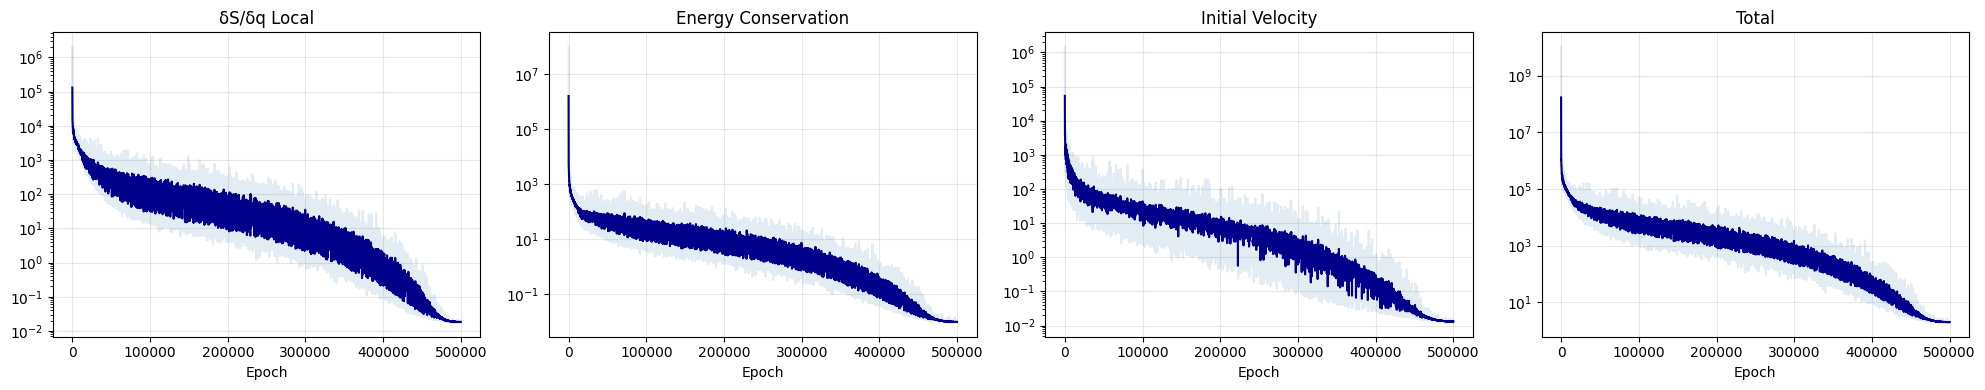

In [12]:
# %% Gráfica de pérdidas
def smooth(v, w=100):
    return np.convolve(v, np.ones(w)/w, mode='valid')

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, key, title in zip(axes,
    ["station", "energy", "vel_ic", "total"],
    ["δS/δq Local", "Energy Conservation", "Initial Velocity", "Total"]):
    raw = np.array(history[key])
    ax.semilogy(raw, alpha=0.15, color='steelblue')
    if len(raw) > 200:
        ax.semilogy(smooth(raw, 200), color='darkblue', lw=1.5)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Results


In [13]:

def generate_testing_map(scale = 2, dm = 0.1):

    x0_min = -10
    x0_max = 10

    y0_min = 0
    y0_max = 20 

    vx0_min = -5
    vx0_max = 5

    vy0_min = 0
    vy0_max = 15

    if scale != 1:
        x_range = x0_max - x0_min
        y_range = y0_max - y0_min 
        vx_range = vx0_max - vx0_min
        vy_range = vy0_max - vy0_min

        x0_min = x0_min - scale * x_range 
        x0_max = x0_max + scale * x_range 

        y0_min = y0_min - scale * y_range 
        y0_max = y0_max + scale * y_range 

        vx0_min = vx0_min - scale * vx_range
        vx0_max = vx0_max + scale * vx_range

        vy0_min = vy0_min - scale * vy_range
        vy0_max = vy0_max + scale * vy_range

    x0_mesh = np.arange(x0_min, x0_max, dm)
    y0_mesh = np.arange(y0_min, y0_max, dm)
    vx0_mesh = np.arange(vx0_min, vx0_max, dm)
    vy0_mesh = np.arange(vy0_min, vy0_max)

    return x0_mesh, y0_mesh, vx0_mesh, vy0_mesh

In [14]:
# %% ============================================================
#    MÓDULO DE COMPARACIÓN: Trayectoria predicha vs analítica
# ================================================================

def plot_trajectory_comparison(model, ic, title_suffix="", display=True):
    x0, y0, vx0, vy0 = ic
    ic_t = torch.tensor(ic, dtype=torch.float32).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(ic_t).cpu().numpy()[0]
    x_nn = np.concatenate([[x0], pred[:N]])
    y_nn = np.concatenate([[y0], pred[N:]])
    x_an, y_an = analytical_trajectory(x0, y0, vx0, vy0)
    x_an = np.concatenate([[x0], x_an])
    y_an = np.concatenate([[y0], y_an])
    t_arr = np.arange(0, N + 1) * dt

    vx_nn = np.diff(x_nn) / dt
    vy_nn = np.diff(y_nn) / dt
    y_mid = (y_nn[1:] + y_nn[:-1]) / 2
    E_nn = 0.5*m*(vx_nn**2+vy_nn**2) + m*9.81*y_mid
    E0_val = 0.5*m*(vx0**2+vy0**2) + m*9.81*y0

    if display:
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        ax = axes[0, 0]
        ax.plot(x_an, y_an, 'k--', lw=2.5, label='Analytic')
        ax.plot(x_nn, y_nn, 'ro-', ms=5, lw=1.5, label='Neural Network', alpha=0.8)
        ax.scatter([x0], [y0], c='green', s=100, zorder=10, label='Start')
        ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
        ax.set_title("Trajectory x-y"); ax.legend()
        ax.grid(True, alpha=0.3); ax.set_aspect('equal')

        ax = axes[0, 1]
        ax.plot(t_arr, x_an, 'b--', lw=2, label='x analytic')
        ax.plot(t_arr, x_nn, 'b^-', ms=4, lw=1, alpha=0.7, label='x NN')
        ax.plot(t_arr, y_an, 'r--', lw=2, label='y analytic')
        ax.plot(t_arr, y_nn, 'rs-', ms=4, lw=1, alpha=0.7, label='y NN')
        ax.set_xlabel("t (s)"); ax.set_ylabel("position (m)")
        ax.set_title("Position vs Time"); ax.legend(ncol=2); ax.grid(True, alpha=0.3)

        ax = axes[1, 0]
        ax.plot(t_arr, np.abs(x_nn - x_an), 'b.-', label='|Δx|')
        ax.plot(t_arr, np.abs(y_nn - y_an), 'r.-', label='|Δy|')
        ax.set_xlabel("t (s)"); ax.set_ylabel("Absolute Error (m)")
        ax.set_title("Absolute Error"); ax.legend(); ax.grid(True, alpha=0.3)

        ax = axes[1, 1]

        ax.plot(E_nn, 'bo-', ms=4, label='E(t) predicted')
        ax.axhline(E0_val, color='r', ls='--', lw=2, label=f'E₀={E0_val:.2f} J')
        ax.set_xlabel("Time step"); ax.set_ylabel("E (J)")
        ax.set_title("Energy Conservation"); ax.legend(); ax.grid(True, alpha=0.3)

        fig.suptitle(f"IC: x₀={x0:.1f}, y₀={y0:.1f}, vx₀={vx0:.1f}, vy₀={vy0:.1f}  "
                    f"{title_suffix}", fontsize=13, fontweight='bold')
        plt.tight_layout(); plt.show()

        rmse_x = np.sqrt(np.mean((x_nn - x_an)**2))
        rmse_y = np.sqrt(np.mean((y_nn - y_an)**2))
        print(f"  RMSE_x={rmse_x:.4f} m | RMSE_y={rmse_y:.4f} m | σ(E)={np.std(E_nn):.4f} J")

    return x_nn - x_an, y_nn - y_an, E_nn - E0_val

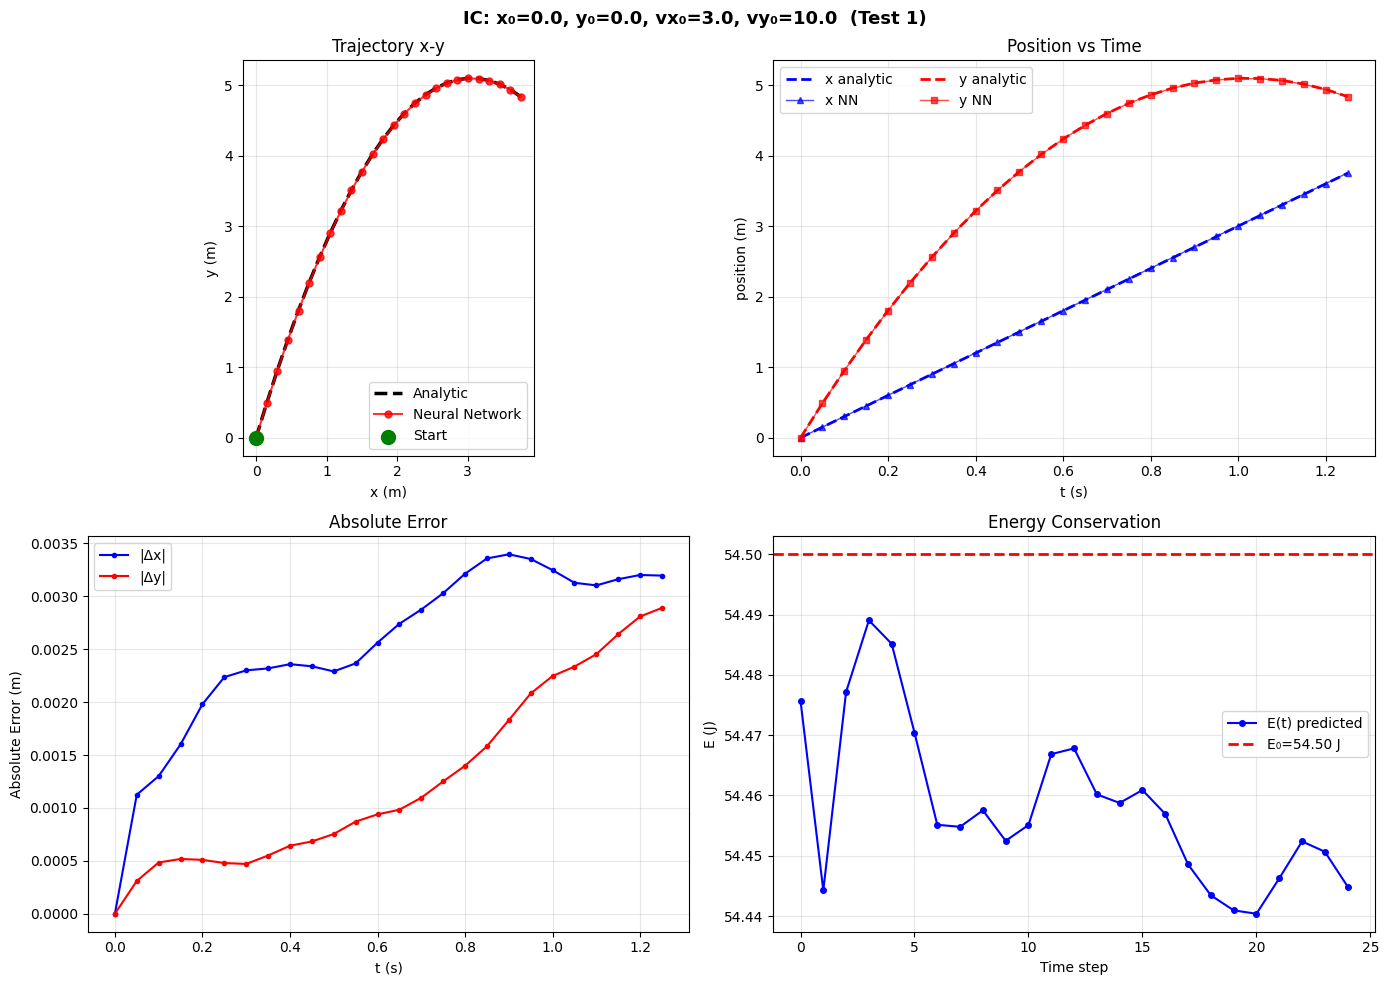

  RMSE_x=0.0027 m | RMSE_y=0.0015 m | σ(E)=0.0131 J


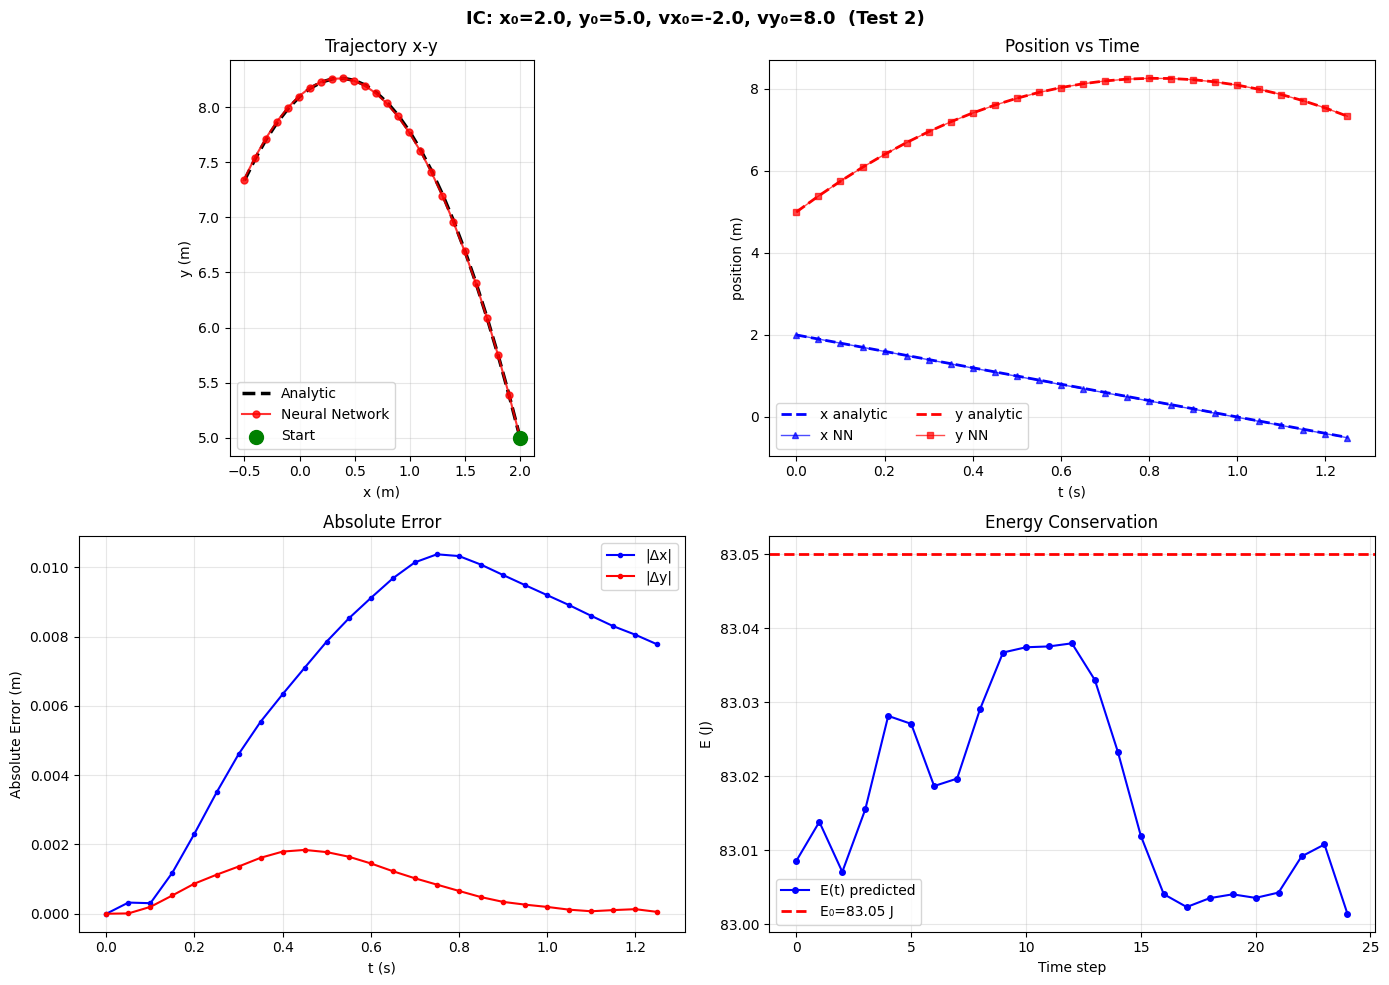

  RMSE_x=0.0076 m | RMSE_y=0.0010 m | σ(E)=0.0126 J


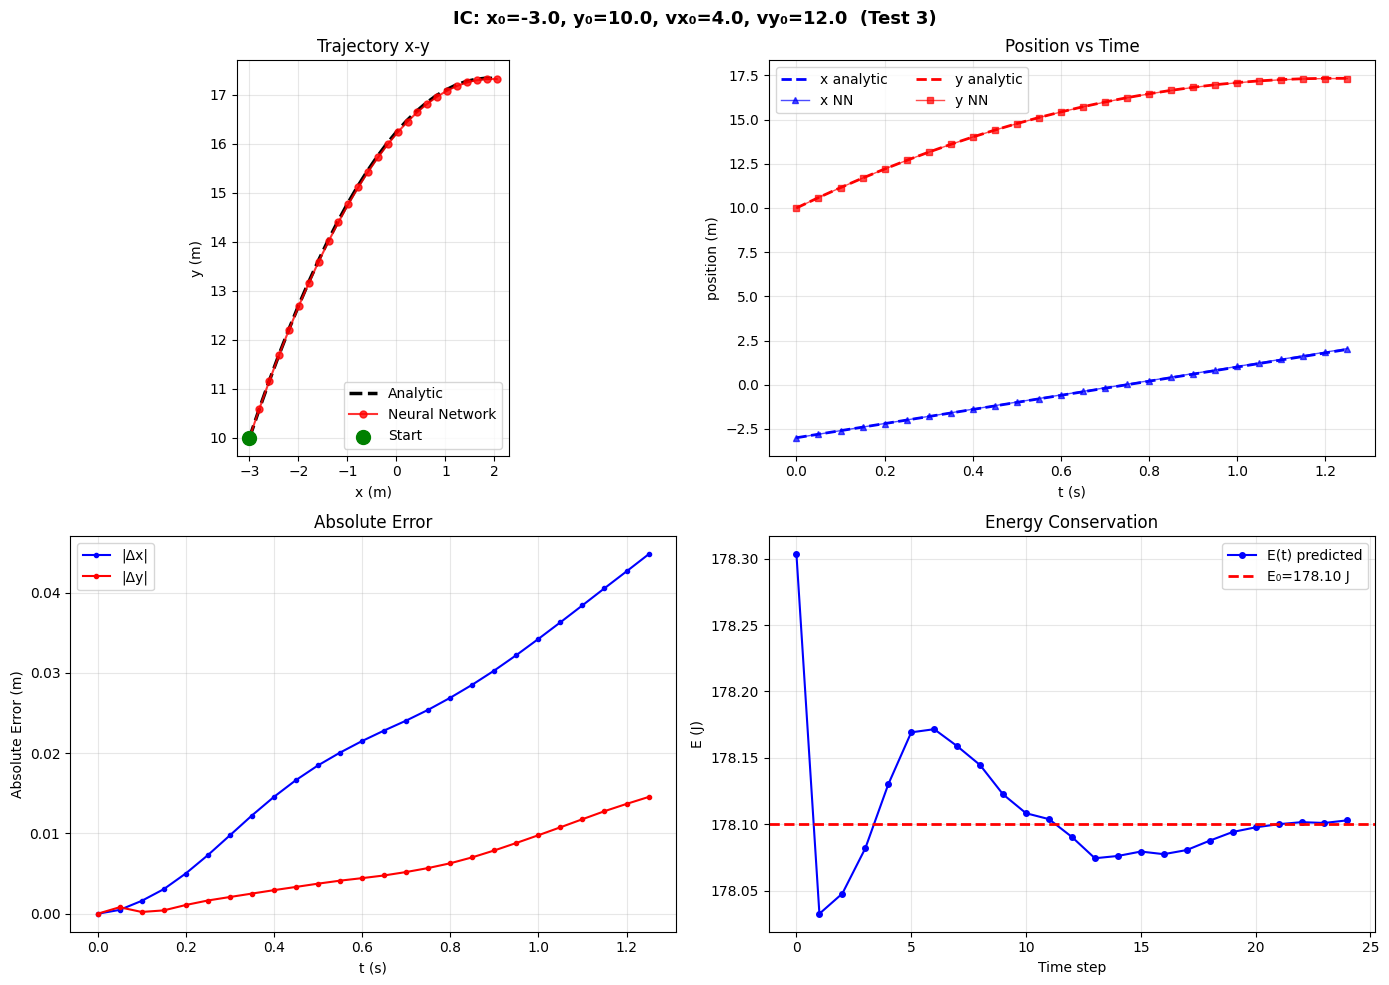

  RMSE_x=0.0254 m | RMSE_y=0.0071 m | σ(E)=0.0515 J


In [15]:
# %% Ejecutar comparaciones
test_conditions = np.array([
    [0.0, 0.0, 3.0, 10.0],
    [2.0, 5.0, -2.0, 8.0],
    [-3.0, 10.0, 4.0, 12.0],
], dtype=np.float32)

for i, ic in enumerate(test_conditions):
    plot_trajectory_comparison(model, ic, title_suffix=f"(Test {i+1})")


In [16]:
# %% Ejecutar comparaciones
test_conditions = generate_batch(10000)

x_errors_vector = []
y_errors_vector = []
energy_errors_vector = []

for i, ic in enumerate(test_conditions):
    x_errors, y_errors, energy_errors = plot_trajectory_comparison(model, ic, title_suffix=f"(Test {i+1})", display=False)
    x_errors_vector.append(x_errors)
    y_errors_vector.append(y_errors)
    energy_errors_vector.append(energy_errors)

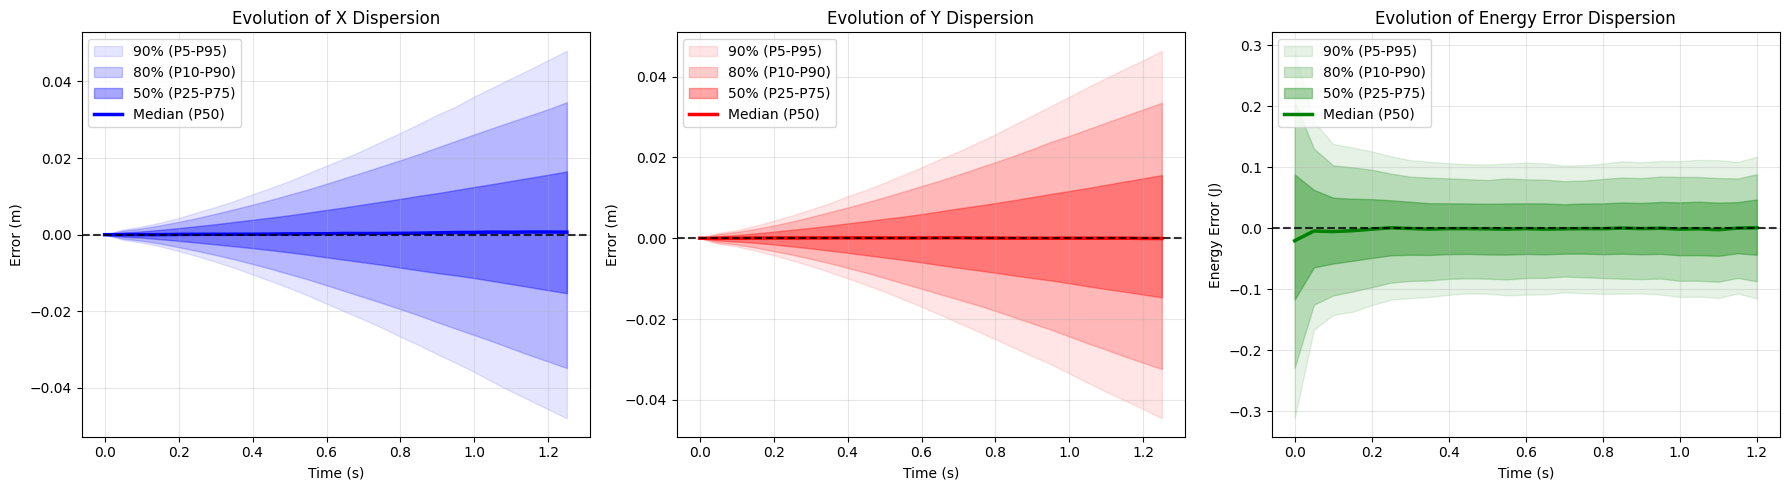

In [17]:
time_vector = np.arange(0, N + 1) * dt

all_x_errors = np.array(x_errors_vector)
all_y_errors = np.array(y_errors_vector)
all_energy_errors = np.array(energy_errors_vector)

# 1. Calcular el Error Medio (Sesgo) conservando el signo
x_mean_err = np.mean(all_x_errors, axis=0)
y_mean_err = np.mean(all_y_errors, axis=0)
energy_mean_err = np.mean(all_energy_errors, axis=0)

# 2. Calcular la Desviación Estándar del error real
x_std = np.std(all_x_errors, axis=0)
y_std = np.std(all_y_errors, axis=0)
energy_std = np.std(all_energy_errors, axis=0)

# (Opcional) Si en el artículo te piden reportar el RMSE, lo calculas así:
# x_rmse = np.sqrt(x_mean_err**2 + x_std**2)


# Extracción de la topología asimétrica mediante percentiles [10%, 50%, 90%]
# El cálculo vectorizado sobre axis=0 procesa los 10,000 batches por cada paso temporal
x_p10, x_median, x_p90 = np.percentile(all_x_errors, [10, 50, 90], axis=0)
y_p10, y_median, y_p90 = np.percentile(all_y_errors, [10, 50, 90], axis=0)
e_p10, e_median, e_p90 = np.percentile(all_energy_errors, [10, 50, 90], axis=0)


# ---------------------------------------------------------
# Creación de los Gráficos
# ---------------------------------------------------------

# 1. Extracción Topológica de Cuantiles Estratificados
percentiles_objetivo = [5, 10, 25, 50, 75, 90, 95]

# Desempaquetado de tensores de cuantiles (cada variable contiene 7 vectores de dimensión N)
x_p5, x_p10, x_p25, x_median, x_p75, x_p90, x_p95 = np.percentile(all_x_errors, percentiles_objetivo, axis=0)
y_p5, y_p10, y_p25, y_median, y_p75, y_p90, y_p95 = np.percentile(all_y_errors, percentiles_objetivo, axis=0)
e_p5, e_p10, e_p25, e_median, e_p75, e_p90, e_p95 = np.percentile(all_energy_errors, percentiles_objetivo, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Parámetros de opacidad para el gradiente de densidad
alpha_outer = 0.1   # Banda del 90% (Más tenue)
alpha_mid = 0.2     # Banda del 80%
alpha_inner = 0.35  # Banda del 50% (Más oscura/focalizada)

# 1. Eje X
axes[0].fill_between(time_vector, x_p5, x_p95, color='blue', alpha=alpha_outer, label='90% (P5-P95)')
axes[0].fill_between(time_vector, x_p10, x_p90, color='blue', alpha=alpha_mid, label='80% (P10-P90)')
axes[0].fill_between(time_vector, x_p25, x_p75, color='blue', alpha=alpha_inner, label='50% (P25-P75)')
axes[0].plot(time_vector, x_median, color='blue', lw=2.5, label='Median (P50)')

axes[0].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[0].set_title("Evolution of X Dispersion")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Error (m)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper left')

# 2. Eje Y
axes[1].fill_between(time_vector, y_p5, y_p95, color='red', alpha=alpha_outer, label='90% (P5-P95)')
axes[1].fill_between(time_vector, y_p10, y_p90, color='red', alpha=alpha_mid, label='80% (P10-P90)')
axes[1].fill_between(time_vector, y_p25, y_p75, color='red', alpha=alpha_inner, label='50% (P25-P75)')
axes[1].plot(time_vector, y_median, color='red', lw=2.5, label='Median (P50)')

axes[1].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[1].set_title("Evolution of Y Dispersion")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Error (m)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper left')

# 3. Energía
time_vector = np.arange(0, N ) * dt
axes[2].fill_between(time_vector, e_p5, e_p95, color='green', alpha=alpha_outer, label='90% (P5-P95)')
axes[2].fill_between(time_vector, e_p10, e_p90, color='green', alpha=alpha_mid, label='80% (P10-P90)')
axes[2].fill_between(time_vector, e_p25, e_p75, color='green', alpha=alpha_inner, label='50% (P25-P75)')
axes[2].plot(time_vector, e_median, color='green', lw=2.5, label='Median (P50)')

axes[2].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[2].set_title("Evolution of Energy Error Dispersion")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Energy Error (J)")
axes[2].grid(True, alpha=0.3)
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.show()

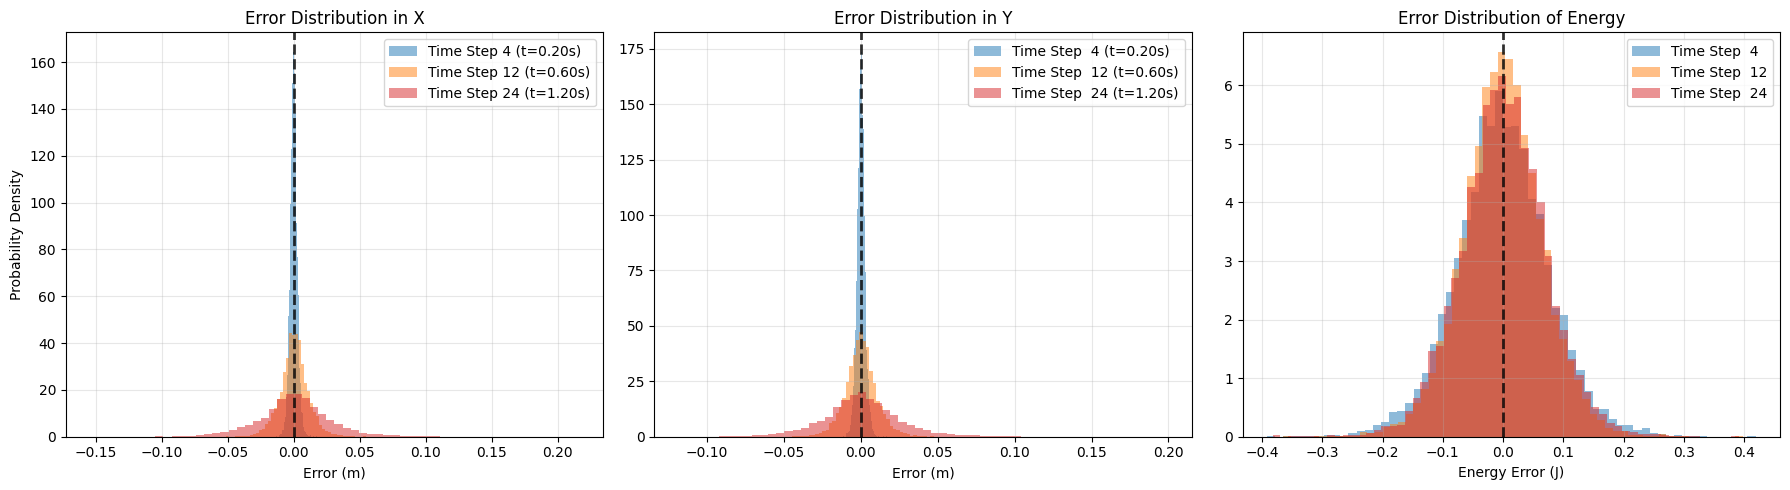

In [18]:

# Definición de los pasos temporales a analizar (ej. inicio, medio, final)
# Asegúrate de que los índices no superen N-1 o la dimensión de tu arreglo
pasos_objetivo = [4, 12, 24] 
colores = ['#1f77b4', '#ff7f0e', '#d62728'] # Azul, naranja, rojo

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ---------------------------------------------------------
# 1. Histograma: Error en Eje X
# ---------------------------------------------------------
for i, paso in enumerate(pasos_objetivo):
    # Extracción del corte transversal en el tiempo 'paso'
    datos_corte = all_x_errors[:, paso]
    
    axes[0].hist(
        datos_corte, 
        bins=60, 
        alpha=0.5, 
        color=colores[i], 
        density=True, # Normalización a PDF para comparar distribuciones
        label=f'Time Step {paso} (t={paso*dt:.2f}s)'
    )
    
axes[0].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[0].set_title("Error Distribution in X")
axes[0].set_xlabel("Error (m)")
axes[0].set_ylabel("Probability Density")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# ---------------------------------------------------------
# 2. Histograma: Error en Eje Y
# ---------------------------------------------------------
for i, paso in enumerate(pasos_objetivo):
    datos_corte = all_y_errors[:, paso]
    
    axes[1].hist(
        datos_corte, 
        bins=60, 
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step  {paso} (t={paso*dt:.2f}s)'
    )
    
axes[1].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[1].set_title("Error Distribution in Y")
axes[1].set_xlabel("Error (m)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# ---------------------------------------------------------
# 3. Histograma: Error en Energía
# ---------------------------------------------------------
for i, paso in enumerate(pasos_objetivo):
    # La matriz de energía puede tener dimensión N-1. Se previene desbordamiento.
    if paso >= all_energy_errors.shape[1]:
        paso_E = all_energy_errors.shape[1] - 1
    else:
        paso_E = paso
        
    datos_corte = all_energy_errors[:, paso_E]
    
    axes[2].hist(
        datos_corte, 
        bins=60, 
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step  {paso_E}'
    )

axes[2].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[2].set_title("Error Distribution of Energy")
axes[2].set_xlabel("Energy Error (J)")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

## Out of Range MSE


In [19]:
x0_mesh, y0_mesh, vx0_mesh, vy0_mesh = generate_testing_map(scale=2, dm = 0.01)

#for i, ic in enumerate(test_conditions):
#    plot_trajectory_comparison(model, ic, title_suffix=f"(Test {i+1})")


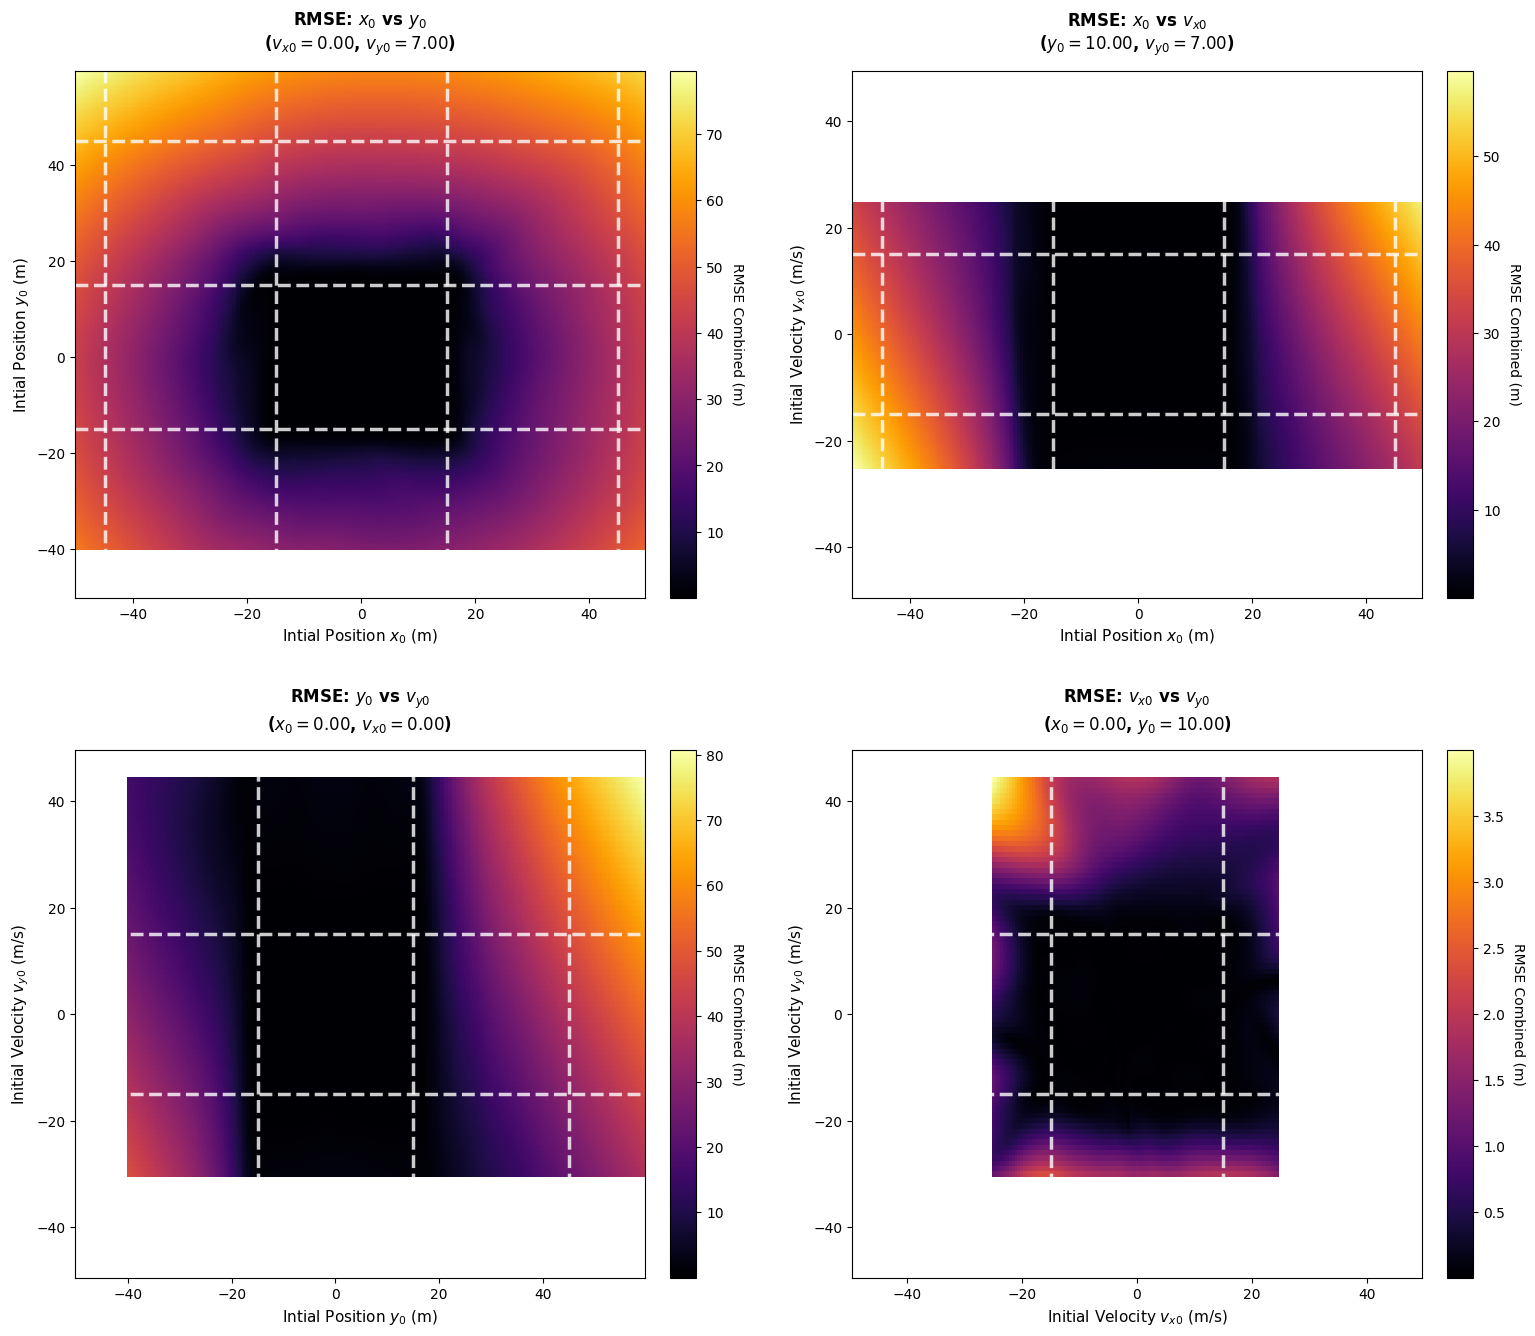

In [20]:


x0_vals, y0_vals, vx0_vals, vy0_vals = generate_testing_map(scale=2, dm = 0.5)


# 2. Extracción de valores centrales invariantes
c_x0 = x0_vals[len(x0_vals) // 2]
c_y0 = y0_vals[len(y0_vals) // 2]
c_vx0 = vx0_vals[len(vx0_vals) // 2]
c_vy0 = vy0_vals[len(vy0_vals) // 2]

def compute_rmse_slice(model, var_x_vals, var_y_vals, fixed_dict, var_names):
    """
    Evalúa el RMSE posicional del modelo sobre un corte 2D del espacio de fase.
    """
    X, Y = np.meshgrid(var_x_vals, var_y_vals)
    flat_X = X.ravel()
    flat_Y = Y.ravel()
    batch_size = len(flat_X)
    
    # Construcción del tensor de entrada (B, 4) -> [x0, y0, vx0, vy0]
    data = np.zeros((batch_size, 4), dtype=np.float32)
    
    # Asignación de variables iterativas y fijas
    mapping = {'x0': 0, 'y0': 1, 'vx0': 2, 'vy0': 3}
    data[:, mapping[var_names[0]]] = flat_X
    data[:, mapping[var_names[1]]] = flat_Y
    
    for fixed_name, fixed_val in fixed_dict.items():
        data[:, mapping[fixed_name]] = fixed_val
        
    batch_tensor = torch.from_numpy(data).to(device)
    
    # Inferencia de la red neuronal
    with torch.no_grad():
        pred = model(batch_tensor).cpu().numpy() # (B, 2*N)
        
    x_nn = pred[:, :N]
    y_nn = pred[:, N:]
    
    # Cálculo analítico vectorizado
    t_arr = np.arange(1, N + 1) * dt
    x0_arr = data[:, 0:1]
    y0_arr = data[:, 1:2]
    vx0_arr = data[:, 2:3]
    vy0_arr = data[:, 3:4]
    
    x_an = x0_arr + vx0_arr * t_arr
    y_an = y0_arr + vy0_arr * t_arr + 0.5 * g * t_arr**2
    
    # RMSE posicional global (m)
    mse_x = np.mean((x_nn - x_an)**2, axis=1)
    mse_y = np.mean((y_nn - y_an)**2, axis=1)
    rmse_total = np.sqrt(mse_x + mse_y)
    
    return X, Y, rmse_total.reshape(X.shape)

# 3. Cálculo de las 4 proyecciones del espacio de fase
slices = [
    {
        'vars': (x0_vals, y0_vals), 'names': ('x0', 'y0'),
        'fixed': {'vx0': c_vx0, 'vy0': c_vy0},
        'labels': ('Intial Position $x_0$ (m)', 'Intial Position $y_0$ (m)'),
        'title': f'RMSE: $x_0$ vs $y_0$\n($v_{{x0}}={c_vx0:.2f}$, $v_{{y0}}={c_vy0:.2f}$)'
    },
    {
        'vars': (x0_vals, vx0_vals), 'names': ('x0', 'vx0'),
        'fixed': {'y0': c_y0, 'vy0': c_vy0},
        'labels': ('Intial Position $x_0$ (m)', 'Initial Velocity $v_{x0}$ (m/s)'),
        'title': f'RMSE: $x_0$ vs $v_{{x0}}$\n($y_0={c_y0:.2f}$, $v_{{y0}}={c_vy0:.2f}$)'
    },
    {
        'vars': (y0_vals, vy0_vals), 'names': ('y0', 'vy0'),
        'fixed': {'x0': c_x0, 'vx0': c_vx0},
        'labels': ('Intial Position $y_0$ (m)', 'Initial Velocity $v_{y0}$ (m/s)'),
        'title': f'RMSE: $y_0$ vs $v_{{y0}}$\n($x_0={c_x0:.2f}$, $v_{{x0}}={c_vx0:.2f}$)'
    },
    {
        'vars': (vx0_vals, vy0_vals), 'names': ('vx0', 'vy0'),
        'fixed': {'x0': c_x0, 'y0': c_y0},
        'labels': ('Initial Velocity $v_{x0}$ (m/s)', 'Initial Velocity $v_{y0}$ (m/s)'),
        'title': f'RMSE: $v_{{x0}}$ vs $v_{{y0}}$\n($x_0={c_x0:.2f}$, $y_0={c_y0:.2f}$)'
    }
]

def obtener_cuatro_referencias(nombre_variable, arreglo_dominio):
    """
    Inyecta 4 valores de referencia ortogonales condicionados a la dimensión del espacio de fase.
    Permite mezclar valores escalares absolutos con extracciones indexadas del dominio de entrada.
    """

    x_range = x_max - x_min
    y_range = y_max - y_min
    vx_range = vx_max - vx_min 
    vy_range = vy_max - vy_min 

    if nombre_variable == 'x0':
        return [x_min - x_range, x_min, x_max, x_max + x_range]
        
    elif nombre_variable == 'y0':
        return [y_min - y_range, y_min, y_max, y_max + y_range]

    elif nombre_variable == 'vx0':
        return [vx_min - vx_range, vx_min, vx_max, vx_max + vx_range]
        
    elif nombre_variable == 'vy0':
        return [vy_min - vy_range, vy_min, vy_max, vy_max + vy_range]
        
    else:
        # Fallback de seguridad (evita excepciones de clave)
        indices = np.linspace(0, len(arreglo_dominio) - 1, 6, dtype=int)[1:-1]
        return arreglo_dominio[indices]

# Se parametriza el diccionario para que contenga listas de 4 valores en lugar de escalares
valores_referencia = {
    'x0': obtener_cuatro_referencias('x0', x0_vals),
    'y0': obtener_cuatro_referencias('y0', y0_vals),
    'vx0': obtener_cuatro_referencias('vx0', vx0_vals),
    'vy0': obtener_cuatro_referencias('vy0', vy0_vals)
}

# 4. Generación de la visualización matricial
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

for i, config in enumerate(slices):
    X, Y, Z_rmse = compute_rmse_slice(
        model, config['vars'][0], config['vars'][1], config['fixed'], config['names']
    )
    
    ax = axes[i]
    im = ax.pcolormesh(X, Y, Z_rmse, cmap='inferno', shading='auto')
    
    # --- INYECCIÓN PARAMETRIZADA DE MÚLTIPLES LÍNEAS ---
    var_x_name = config['names'][0]
    var_y_name = config['names'][1]
    
    # Extraer los arreglos de 4 valores para los ejes actuales
    refs_x = valores_referencia[var_x_name]
    refs_y = valores_referencia[var_y_name]
    
    # Trazar las 4 líneas verticales
    for val_x in refs_x:
        ax.axvline(
            x=val_x, 
            color='white', 
            linestyle='--', 
            linewidth=2.5,  # Ligeramente reducido de 3.0 para no saturar la malla
            alpha=0.8
        )
        
    # Trazar las 4 líneas horizontales
    for val_y in refs_y:
        ax.axhline(
            y=val_y, 
            color='white', 
            linestyle='--', 
            linewidth=2.5, 
            alpha=0.8
        )
    # --------------------------------------------------
    
    ax.set_title(config['title'], fontsize=12, fontweight='bold', pad=15)
    ax.set_xlabel(config['labels'][0], fontsize=11)
    ax.set_ylabel(config['labels'][1], fontsize=11)
    
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('RMSE Combined (m)', rotation=270, labelpad=15)

plt.tight_layout(pad=3.0)
plt.show()

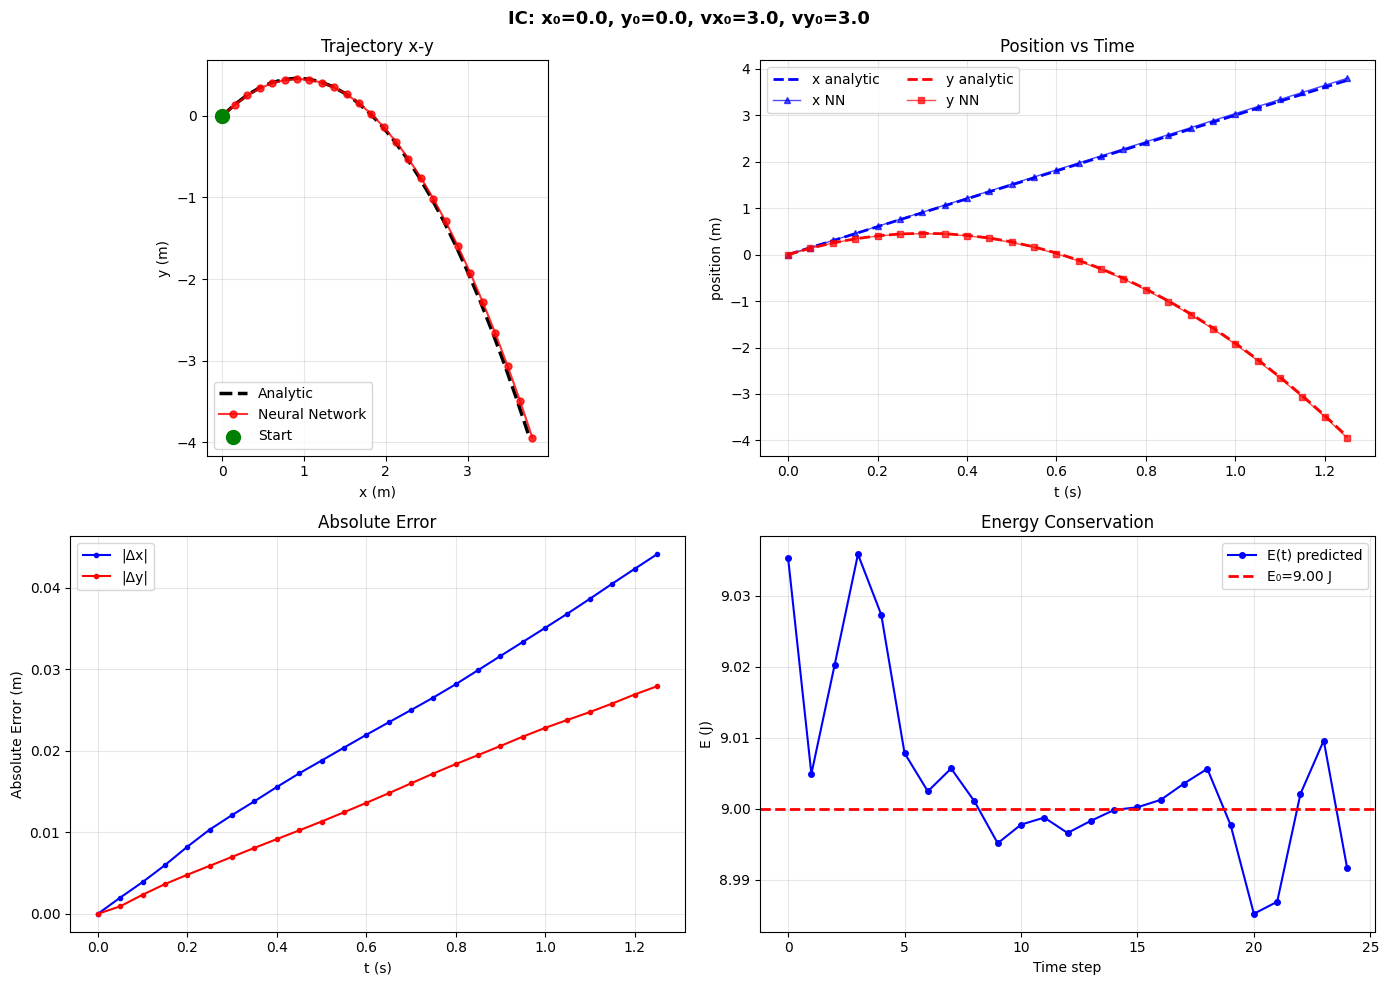

  RMSE_x=0.0259 m | RMSE_y=0.0165 m | σ(E)=0.0126 J


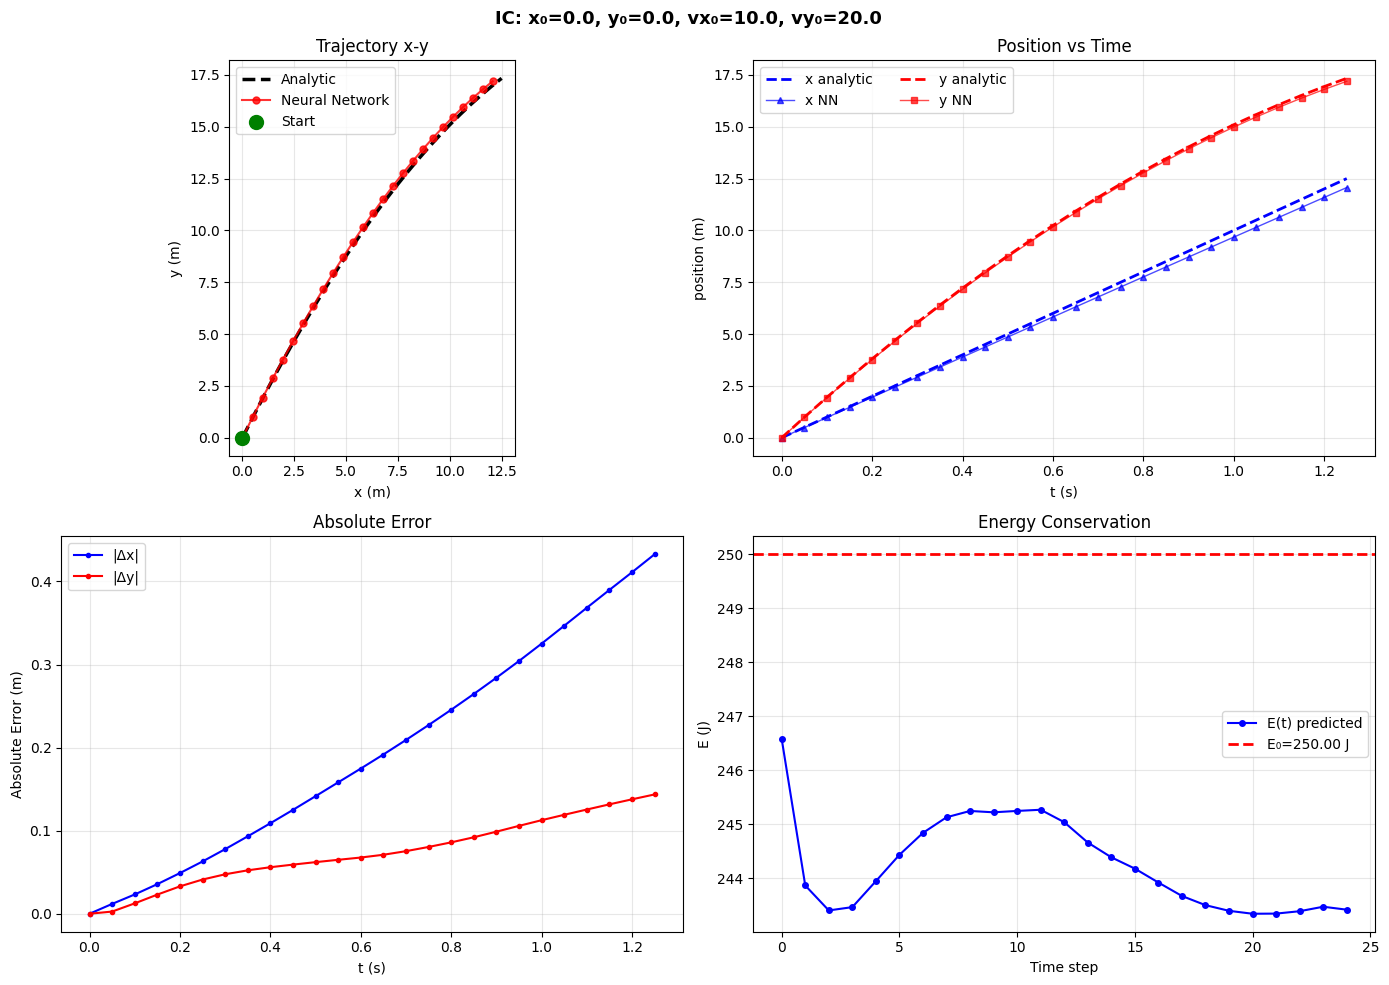

  RMSE_x=0.2346 m | RMSE_y=0.0835 m | σ(E)=0.8567 J


In [22]:

# %% Ejecutar comparaciones
test_conditions = np.array([
    [0.0, 0.0, 3, 3], # Inside the training domain 
    [0.0, 0.0, 10.0, 20.0], # Outside the training domain
], dtype=np.float32)

for i, ic in enumerate(test_conditions):
    plot_trajectory_comparison(model, ic, title_suffix=f"")